## GPT2 Architecture Part 7: Generate text from output Tensor

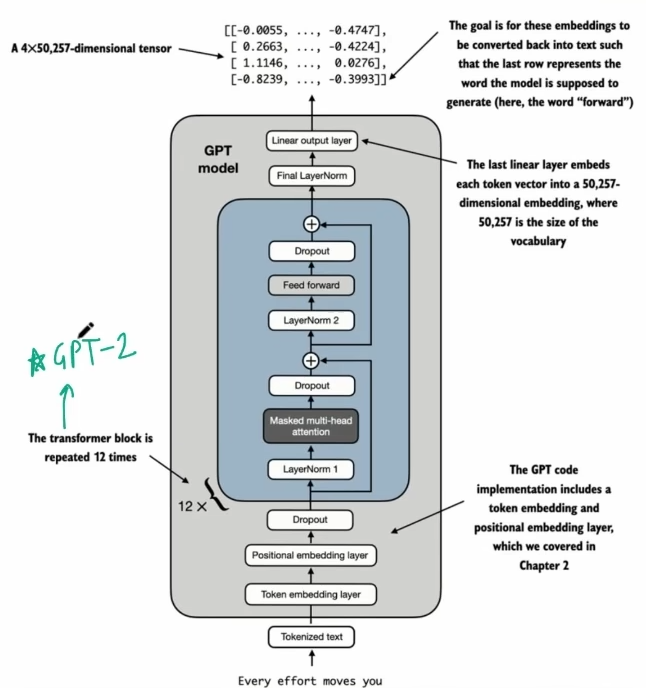

In [7]:
from IPython.display import Image
Image("images/stage1_6_GPT2_model/GPT2_model.png", width=600)

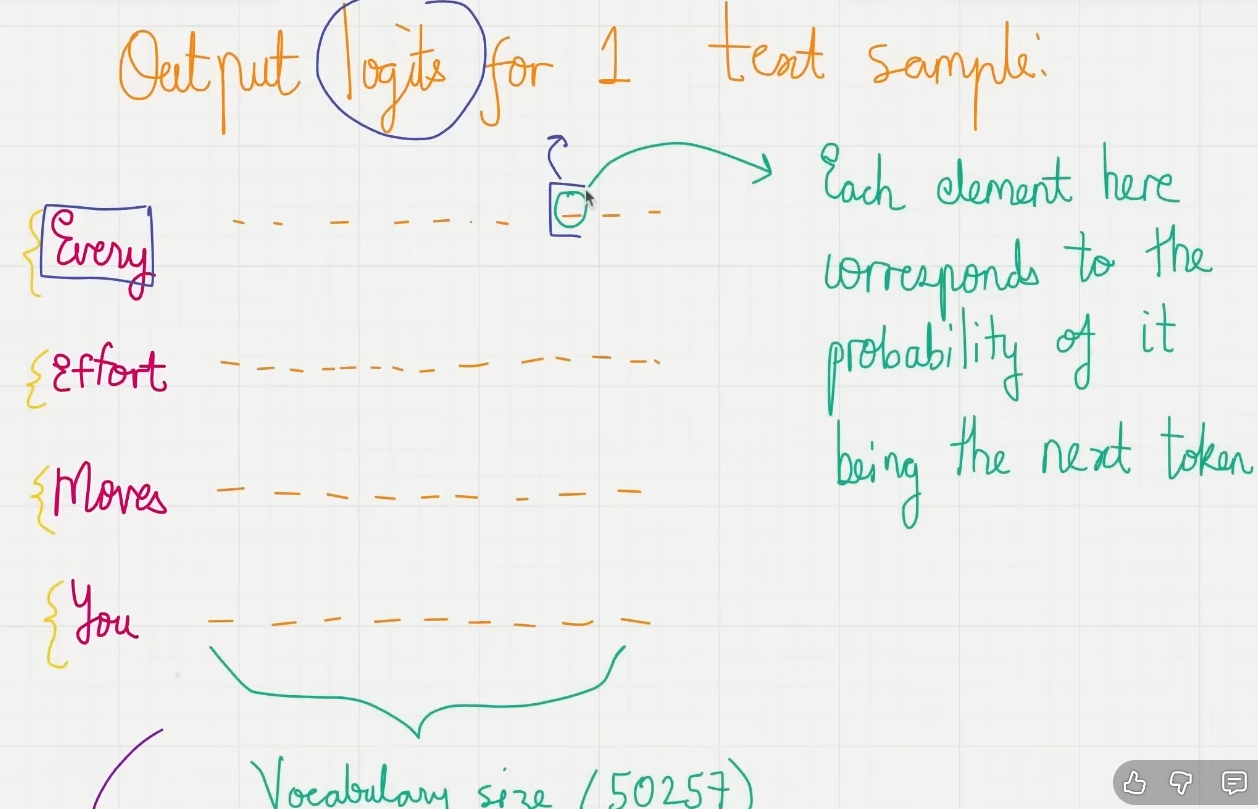

In [6]:
Image("images/stage1_6_GPT2_model/output_logit.png", width=400)

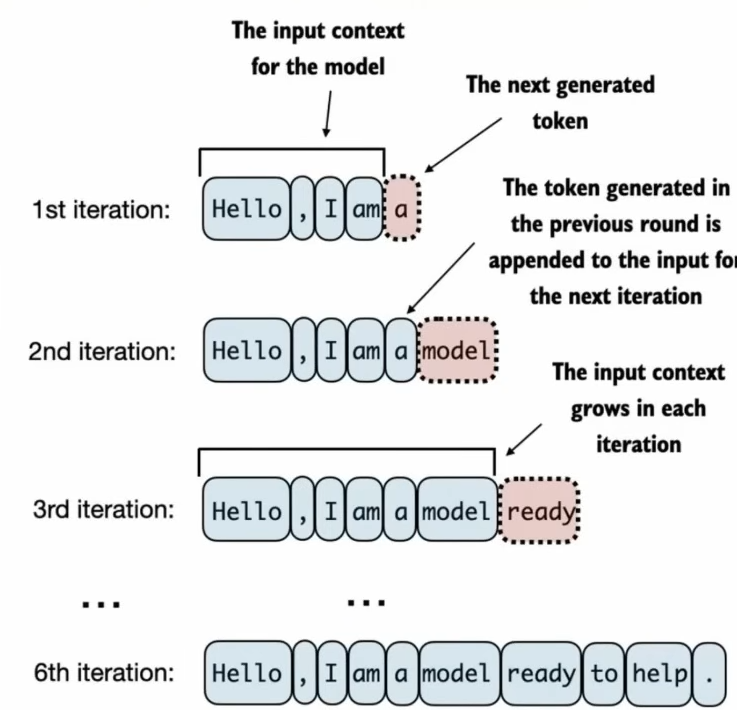

In [5]:
Image("images/stage1_6_GPT2_model/next_word_prediction_flow.png", width=400)

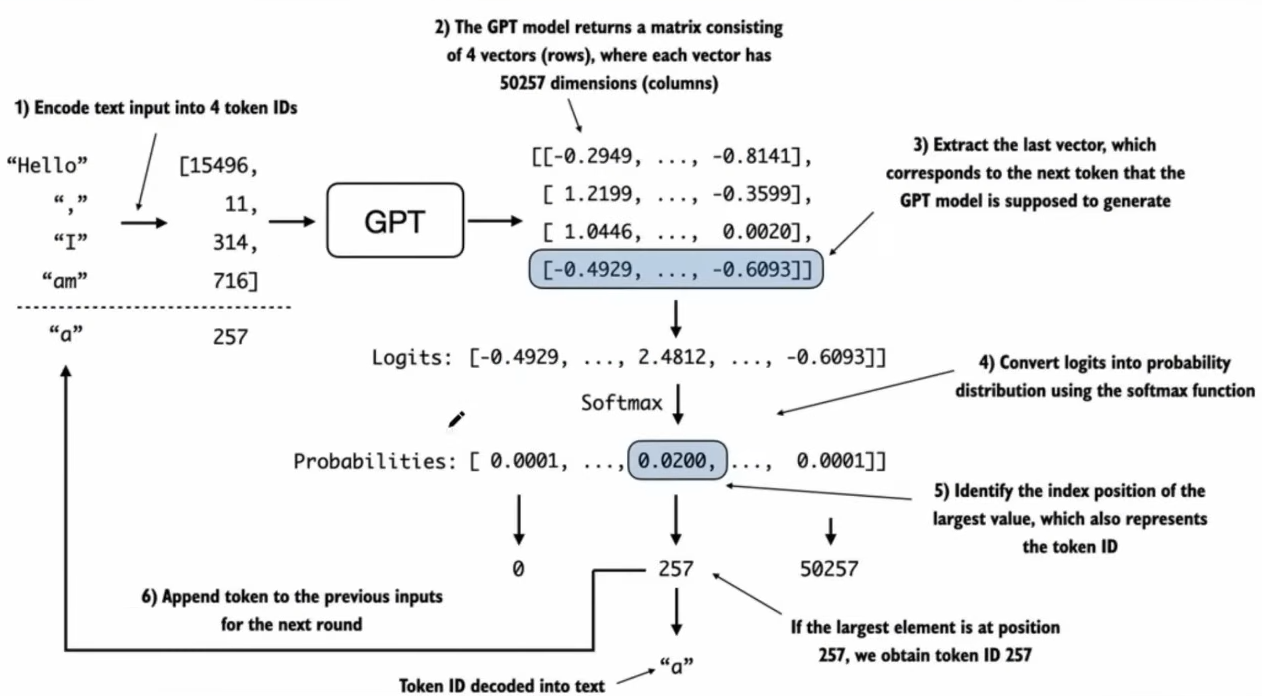

In [11]:
Image("images/stage1_6_GPT2_model/next_word_prediction_tensor.png", width=800)

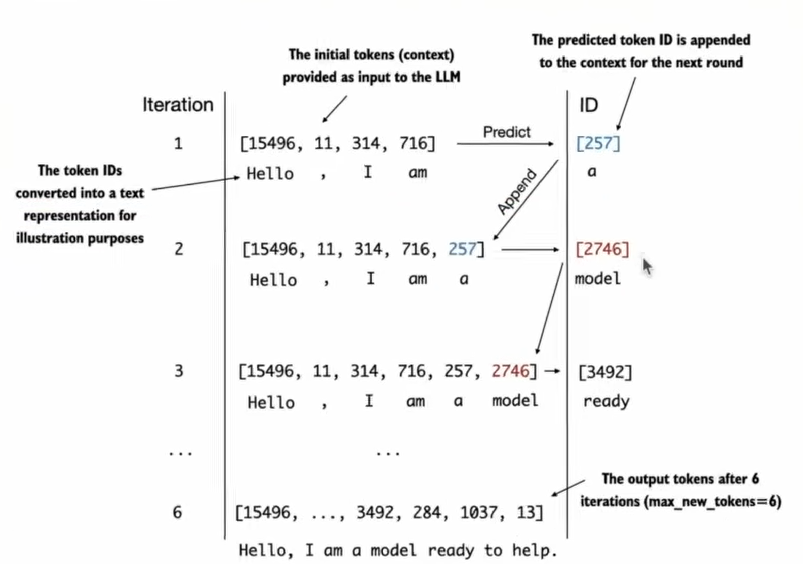

In [9]:
Image("images/stage1_6_GPT2_model/next_word_prediction_iteration-wise.png", width=600)

In [12]:
import torch
import torch.nn as nn
torch.set_printoptions(sci_mode=False)



In [13]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size of the model
    "context_length": 1024,  # Maximum context length for the model
    "emb_dim": 768,          # Embedding dimension of the model
    "n_heads": 12,           # Number of attention heads in the model
    "n_layers": 12,          # Number of transformer layers in the model
    "drop_rate": 0.1,        # Dropout rate for regularization
    "qkv_bias": True         # Whether to include bias terms in the query, key, and value projections
}

### The Building Blocks: Layer Normalization, GELU and Feed-forward network

In [14]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))


    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # (b, num_tokens, d_out)
        queries = self.W_query(x)  # (b, num_tokens, d_out)
        values = self.W_value(x)  # (b, num_tokens, d_out)

        # we implicitly split the matrix by adding a new dimension for the heads "num_heads"
        # unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # transpose to get dimensions: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        # we wan th grouping to be the heads, so we swap the num_heads and num_tokens dimensions not on tokens

        keys = keys.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        queries = queries.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        values = values.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)

        # compute scaled dot product attention (aka slef attention) with a causal mask
        # we compute the attention scores by taking the dot product of the queries and keys
        attn_scores = queries @ keys.transpose(2, 3)  

        # original mask truncated to the number of tokens in the input and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # use the mask to fill the attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        # calculate the attention weights by applying softmax to the attention scores
        # # keys.shape[-1] is the head_dim, we scale the attention scores by the square root of the head dimension 
        # to prevent them from getting too large
        attn_weights = torch.softmax(attn_scores/keys.shape[-1]**0.5, dim=-1) 
        attn_weights = self.dropout(attn_weights)

        # calculate context vector as the weighted sum of the values, using the attention weights
        # transpose to keep num_heads & head_dim together for the output
        context_vec = (attn_weights @ values).transpose(1,2)

        # combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec




In [15]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True) # calculate row-wise mean
        var = x.var(dim=-1, keepdim=True, unbiased=False) # calculate row-wise variance
        x_norm = (x - mean) / torch.sqrt(var + self.eps) # eps is added to avoid division by zero
        return self.scale * x_norm + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))
    

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),  ## Expansion
            GELU(), ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])   ## Contraction
        )

    def forward(self, x):
        return self.layers(x)
    

### Let's Build entire Transformer Block

- Step 1: Shortcut connection for attention block

- Step 2: Shortcut connection for feed forward block

- Step 3: Add the original input back

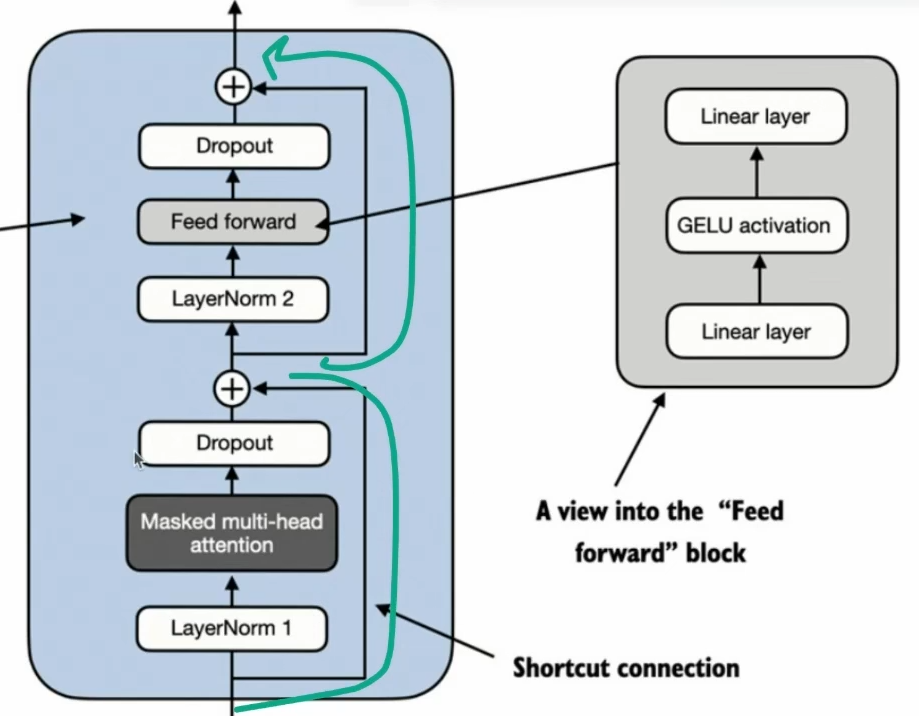

In [16]:
Image("images/stage_1_4_shortcut_conn/shorcut_in_transformer.png", width=700)

In [22]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
                    d_in=cfg["emb_dim"], 
                    d_out=cfg["emb_dim"], 
                    context_length=cfg["context_length"], 
                    num_heads=cfg["n_heads"], 
                    dropout=cfg["drop_rate"], 
                    qkv_bias=cfg["qkv_bias"])

        self.ff = FeedForward(cfg)

        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])

        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
        


    def forward(self, x):
        # first part: layer_norm -> attention -> dropout -> add shortcut

        # shorcut connection for transformer block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # shape = (batch_size, num_tokens, emb_dim)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        # second part: layer_norm -> feedforward -> dropout -> add shortcut
        
        # shorcut connection for transformer block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        return x



- Layer normalization is applied before each of 2 components, and dropout is applied after them to regularize the model and reduce overfitting.

- This is also known as Pre-LayerNorm

- Older architectures, such as original transformer model, appied layer normalizaion after the self-attention and feed-forward network instead, known as POST-LAYERNORM, which often leads to worse training dynamics.

- The class also implements the forward pass, where each component is followed by a shortcut connection that adds the input of the block to its output. This critical feature helps gradient flow through the network during training and improves the learnig of deep models.

## GPT-2 model

In [23]:
class GPTmodel(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.tok_emb = nn.Embedding(config["vocab_size"], config["emb_dim"])
        self.pos_emb = nn.Embedding(config["context_length"], config["emb_dim"])
        self.drop_emb = nn.Dropout(config["drop_rate"])

        # 12 transformer blocks, each with 12 attention heads and 768 embedding dimensions
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(config) for _ in range(config["n_layers"])])

        # ApplyLayerNorm
        self.final_norm = LayerNorm(config["emb_dim"])
        self.out_head = nn.Linear(config["emb_dim"], config["vocab_size"], bias=False)


    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        # step1: Get token embeddings
        tok_emb = self.tok_emb(in_idx)  # Token embeddings

        # step2: Get positional embeddings
        pos_emb = self.pos_emb(torch.arange(seq_len, device=in_idx.device))  # Positional embeddings
        x = tok_emb + pos_emb  # Combine token and positional embeddings

        # step3: Apply dropout to the combined embeddings
        x = self.drop_emb(x)

        # step4: Pass through transformer blocks
        x = self.trf_blocks(x)

        # step5: Apply final layer normalization
        x = self.final_norm(x)

        # step6: Compute logits for the vocabulary
        logits = self.out_head(x)
        return logits

<div class="alert alert-block alert-warning">

- The init constructor of this GPT model initializes the token and positional embedding layer using the configuration passed.

- These embedding layers are responsible for converting the input token indices into dense vectors and assing positional information


- Next, the init method creates a sequential stack of Transformer Block modules equal to the number of layers specified in config.

- Following the Transformer Block, a LayerNorm is applied, standardizing the output from the transformer block to stabilize learning.

- Finally a linear output head without bias is defined, which projects the transormer's output into the vocabulary space of the tokenizer to generate logits for each token in the vocabulary.

- The forward method takes the batch of input token indices, computes their embeddings, applies the positional embedding, passes the sequence through the transformer block, normalizes the final output, and then compues the logits , representing the next token's unnormalized probabilities. We will convert those logits into tokens and text outputs.

</div>

#### Let's instaniate the GPT model

In [24]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [25]:
torch.manual_seed(123)  # For reproducibility
model = GPTmodel(GPT_CONFIG_124M)
out = model(batch)

print("Input batch:", batch)
print("\nInput shape:\n", batch.shape)
print("\nOutput shape:\n", out.shape)
print("\nOutput logits:\n", out)

Input batch: tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Input shape:
 torch.Size([2, 4])

Output shape:
 torch.Size([2, 4, 50257])

Output logits:
 tensor([[[-0.4546,  0.0081, -0.3693,  ..., -0.1397, -0.3408, -0.0404],
         [ 0.5395, -0.5098,  1.0554,  ..., -0.5960, -0.3028, -0.2684],
         [ 0.0478, -0.2459, -0.3739,  ..., -0.4117, -0.3174, -0.1074],
         [ 0.0547,  0.3506,  0.4306,  ..., -0.0702,  0.3131,  0.1302]],

        [[-0.4348, -0.5515, -0.0093,  ...,  0.0666, -0.3099,  0.0341],
         [-0.2447, -0.8705,  1.5947,  ..., -0.7661, -0.6889,  0.1404],
         [-0.2036, -0.6698, -0.4476,  ..., -0.1229, -0.8122,  0.4316],
         [-0.0733,  1.2139,  0.2007,  ..., -0.0809, -0.4936, -0.5157]]],
       grad_fn=<UnsafeViewBackward0>)


- The output Tensor has shape [2, 4, 50257] since we passed 2 input texts with 4 tokens each.

- The last dimension is the vocabulary size of the tokenizer

In [26]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters in the model: {total_params}")

Total number of parameters in the model: 163037184


- Earlier we spoke of inializing a 124 million parameter GPT model, so why the actual number of parameters are 163 million, as shown in the output ?

#### Weight Tying

- Reason is a concept called weight tying that is used in the original GPT-2 architecture, which means that the original GPT-2 architecture is reusing the weights from the token embedding layer in its output layer.



In [27]:
print("Token embedding layer shape: ", model.tok_emb.weight.shape)
print("Output head layer shape: ", model.out_head.weight.shape)

Token embedding layer shape:  torch.Size([50257, 768])
Output head layer shape:  torch.Size([50257, 768])


In [28]:
total_params_gpt2 = total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Total number of trainable parameters in the GPT-2 model: {total_params_gpt2}")

Total number of trainable parameters in the GPT-2 model: 124439808


- Weight tying actually reduces the overall memory footprints and computational complexity of the model

## Memory requirements for GPT-2 model

In [29]:
total_size_bytes = total_params * 4 
total_size_MB = total_size_bytes / (1024 * 1024)
print(f"Total size of the model in bytes: {total_size_bytes} bytes")
print(f"Total size of the model in MB: {total_size_MB:.2f} MB")

Total size of the model in bytes: 652148736 bytes
Total size of the model in MB: 621.94 MB


## Part7: Generating Text from Input Token

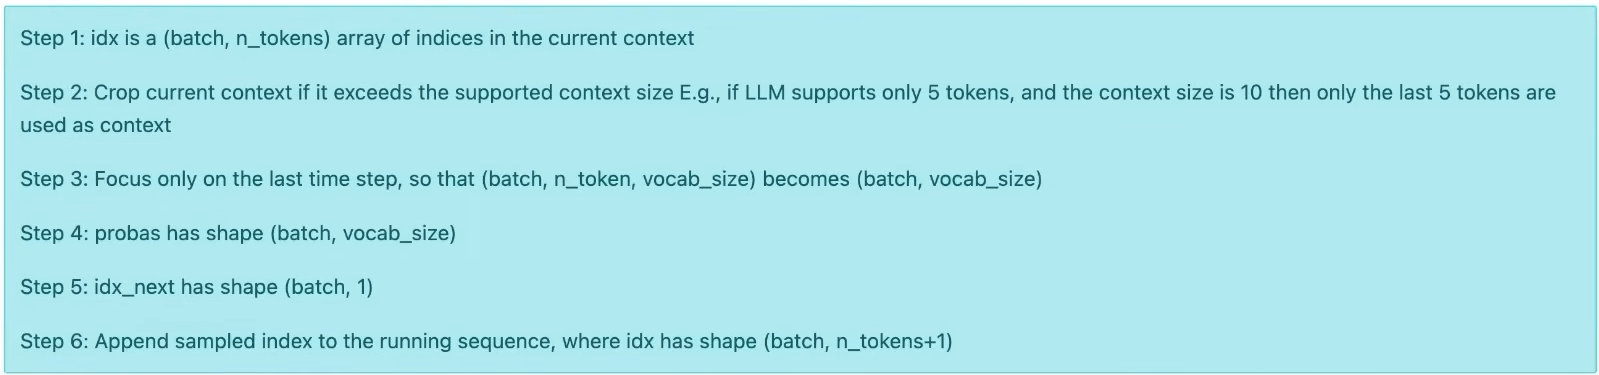

In [30]:

Image("images/stage1_6_GPT2_model/next_word_generation.png", width=800)

- Input

idx is input in batches like below:

Input batch: 

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
"""

In [31]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    
    for _ in range(max_new_tokens):
        # crop idx to the last context_size tokens
        idx_cond = idx[:, -context_size:]

        # get logits for the next token
        with torch.no_grad():  # Disable gradient calculation for inference
            logits = model(idx_cond) ### batch, n_tokens, vocab_size

        # focus on the last time step
        # batch, n_tokens, vocab_size -> batch, vocab_size
        logits = logits[:, -1, :]

        # apply softmax to get probabilities
        # applied along the vocab dimension to get probabilities for each token in the vocabulary
        probs = torch.softmax(logits, dim=-1) 

        # get the idx of the token with the highest probability
        idx_next = torch.argmax(probs, dim=-1, keepdim=True) 

        # append sampled token to the sequence
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

- Softmax function is monotonic, meaning it preserves the order of its input when transformed into outputs.

- So, in practice, the softmax step is redundant, since the position with the highest score in the softmax output tensor is the same 

- I other words, we could simply apply torch.argmax function to the logits tensor directly and get the identical results.

- However, we coded the conversation to illustrate the full process of transforming logits to probabilities, which can add intution, such as that the model generates the most likely next token, which is known as greedy decoding.


- Later we can implement and introduce additional sampling techniques where we modify the softmax outputs such that the model doesn't always slect the most likely token, which introduces variability and creativity in the generated response.

In [34]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("Encoded input:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # Add batch dimension
print("Encoded tensor shape:", encoded_tensor.shape)

Encoded input: [15496, 11, 314, 716]
Encoded tensor shape: torch.Size([1, 4])


In [35]:
model.eval()  # Set the model to evaluation mode

out = generate_text_simple(model=model, 
                           idx=encoded_tensor, 
                           max_new_tokens=6, 
                           context_size=GPT_CONFIG_124M["context_length"])

print("Generated token indices:", out)
print("Output length:", len(out[0]))

Generated token indices: tensor([[15496,    11,   314,   716,  3127, 29991,  6539, 21826, 18530,  6276]])
Output length: 10


In [36]:
# decode the generated token indices back to text
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print("Decoded generated text:", decoded_text)

Decoded generated text: Hello, I am network BEL Afghan postp aired technical


- The reason why model is generating random text is because, we haven't trained the model yet